<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2011%20PBL/Praktikum%204%20(JS11)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 0 & 1 - Load Dataset & Inspeksi Data Teks Review

In [3]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset cafes.csv dan reviews.csv
cafes_df = pd.read_csv('cafes.csv')
reviews_df = pd.read_csv('reviews.csv')

print("Jumlah data cafe:", cafes_df.shape)
print("Jumlah data review:", reviews_df.shape)

# Inspeksi beberapa data teks review pertama
print("\nContoh Teks Review Pengguna:")
print(reviews_df[['author_name', 'rating', 'text']].head(5))

Jumlah data cafe: (99, 12)
Jumlah data review: (2230, 8)

Contoh Teks Review Pengguna:
                 author_name  rating  \
0  Alicia K. Taruli Manurung     5.0   
1                seobchwi fb     5.0   
2              Nico Julianda     5.0   
3            nazira parsa_04     5.0   
4               dulkamdi dul     5.0   

                                                text  
0                                              Hore!  
1  Pelayanan bagus dan ramah apalagi barista yg p...  
2  comfort places for everything i did, mulai dar...  
3    minumannya enak", tempatnya comfy. worth to try  
4  kopian 24jam enak banget kalau dibuat wfc, tem...  


#Langkah 2 - Pra Pengolahan Data Teks & Reduksi Dimensi (PCA)

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD as PCA # Menggunakan TruncatedSVD untuk sparse matrix teks
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Membersihkan data dari missing value pada kolom teks review
reviews_clean = reviews_df.dropna(subset=['text', 'rating']).copy()

# Membatasi sampel (misal 1000 data teratas agar komputasi efisien dan cepat)
reviews_subset = reviews_clean.head(1000)

# Ekstraksi fitur teks menggunakan TF-IDF
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X_text = vectorizer.fit_transform(reviews_subset['text'])

# Membuat label target biner (Misal: 1 jika rating review >= 4.0, 0 jika < 4.0)
y = (reviews_subset['rating'] >= 4.0).astype(int).values

# Pipeline dengan PCA (TruncatedSVD untuk data teks) dan SVC (RBF)
pca = PCA(n_components=50, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam 1 eksekusi
model = make_pipeline(pca, svc)
print("Pipeline PCA + SVM Berhasil Dibuat!")
print("Dimensi data setelah ekstraksi TF-IDF:", X_text.shape)

Pipeline PCA + SVM Berhasil Dibuat!
Dimensi data setelah ekstraksi TF-IDF: (1000, 2000)


#Langkah 3 - Split Data (Training dan Testing)

In [5]:
from sklearn.model_selection import train_test_split

# Pemisahan data training dan data testing dari sparse matrix X_text
Xtrain, Xtest, ytrain, ytest = train_test_split(X_text, y, test_size=0.2, random_state=42)

print("Jumlah data training:", Xtrain.shape[0])
print("Jumlah data testing:", Xtest.shape[0])

Jumlah data training: 800
Jumlah data testing: 200


#Langkah 4 - Pembuatan Model + Hyperparameter Tuning (GridSearchCV)

In [9]:
from sklearn.model_selection import GridSearchCV

# Menentukan grid hyperparameter yang akan diuji
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

grid = GridSearchCV(model, param_grid, cv=3, n_jobs=-1)

# Melakukan fitting GridSearchCV
print("Sedang melakukan GridSearchCV...")
grid.fit(Xtrain, ytrain)

print("Parameter terbaik:", grid.best_params_)
print("Skor akurasi terbaik:", grid.best_score_)

# Menggunakan model terbaik untuk proses prediksi
best_model = grid.best_estimator_
yfit = best_model.predict(Xtest)

Sedang melakukan GridSearchCV...
Parameter terbaik: {'svc__C': 50, 'svc__gamma': 0.005}
Skor akurasi terbaik: 0.8300010325439066


#Langkah 5 - Cek Hasil Prediksi pada Teks Review

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128557 (\N{LOUDLY CRYING FACE}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


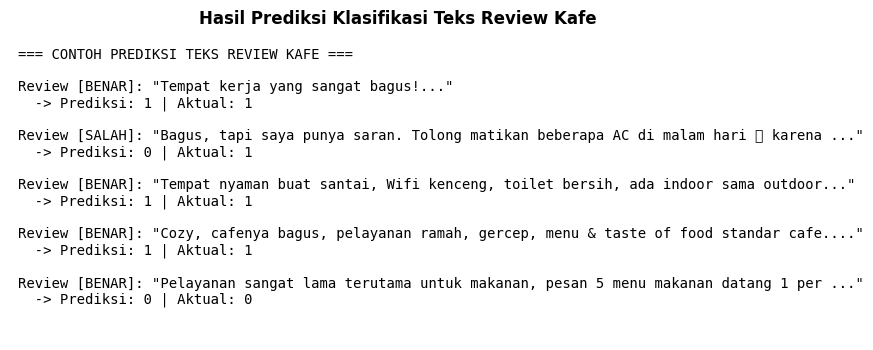

In [10]:
# Mengambil teks asli dari data testing index
test_indices = train_test_split(reviews_subset.index, test_size=0.2, random_state=42)[1]
test_texts = reviews_subset.loc[test_indices, 'text'].values

# Menampilkan beberapa hasil prediksi teks review
fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')

result_summary = "=== CONTOH PREDIKSI TEKS REVIEW KAFE ===\n\n"
for i in range(min(5, len(yfit))):
    status = "BENAR" if yfit[i] == ytest[i] else "SALAH"
    result_summary += f"Review [{status}]: \"{test_texts[i][:80]}...\"\n"
    result_summary += f"  -> Prediksi: {yfit[i]} | Aktual: {ytest[i]}\n\n"

ax.text(0.01, 0.95, result_summary, fontsize=10, verticalalignment='top', family='monospace')
plt.title('Hasil Prediksi Klasifikasi Teks Review Kafe', fontsize=12, fontweight='bold')
plt.show()

#Langkah 6 - Cek Performansi (Classification Report & Confusion Matrix)

Laporan Klasifikasi Performa Model SVM pada Teks Review:
              precision    recall  f1-score   support

           0       0.39      0.85      0.54        26
           1       0.97      0.80      0.88       174

    accuracy                           0.81       200
   macro avg       0.68      0.83      0.71       200
weighted avg       0.90      0.81      0.84       200



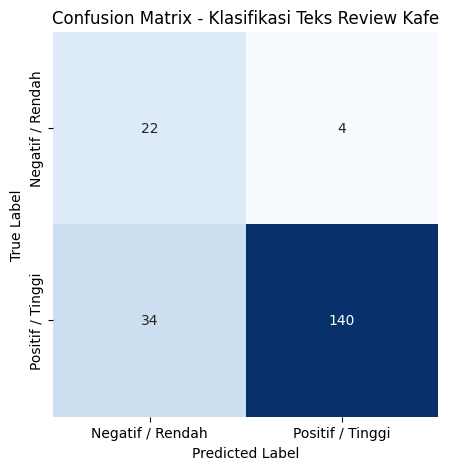

In [11]:
from sklearn.metrics import classification_report, confusion_matrix

# Menampilkan laporan klasifikasi performa model
print("Laporan Klasifikasi Performa Model SVM pada Teks Review:")
print(classification_report(ytest, yfit))

# Membuat Confusion Matrix
mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(6, 5))
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['Negatif / Rendah', 'Positif / Tinggi'],
            yticklabels=['Negatif / Rendah', 'Positif / Tinggi'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Klasifikasi Teks Review Kafe')
plt.show()